# Per-star NLE — dwarf spheroidal likelihood

Trains a conditional flow for `p(observables | theta, cond)`, then runs MCMC (with diagnostics) to recover `theta` for one galaxy and plots the implied density + anisotropy profiles.

`theta` = inferred parameters; `cond` = measured half-light radius (fixed at inference). The model only does per-star `log_prob` / `sample`; the i.i.d. sum, prior, and MCMC live outside it.

In [1]:
%matplotlib inline
import numpy as np
import torch
import matplotlib.pyplot as plt
import pytorch_lightning as pl
import emcee
import corner
import arviz as az

import datasets
from nle import NLE
from transforms import build_transformation, StarBatch

torch.set_num_threads(8)   # shared node: don't grab all CPUs
plt.style.use('/home/tvnguyen/default.mplstyle')

## Load data

`labels` = inferred theta (7); `cond_labels` = measured conditioning (half-light radius).

In [2]:
node_feats, graph_feats = datasets.read_datasets(
    root='/scratch/tvnguyen/datasets', name='8p_ZhaoPlumCOM', num_datasets=1)

labels = (
    'dm_alpha', 'dm_beta', 'dm_gamma', 'dm_log_rdm', 'dm_log_rho0',
    'df_beta0', 'df_log_ra',
)
cond_labels = ('stellar_log_rstar_kpc',)

num_galaxies = 500
num_stars = graph_feats['num_stars'][:num_galaxies]
n_nodes = int(num_stars.sum())
node_feats = {k: v[:n_nodes] for k, v in node_feats.items()}
graph_feats = {k: v[:num_galaxies] for k, v in graph_feats.items()}
print(f'{num_galaxies} galaxies, {n_nodes} stars')


  0%|          | 0/1 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:00<00:00,  3.81it/s]


100%|██████████| 1/1 [00:00<00:00,  3.80it/s]

500 galaxies, 49057 stars


## Observation pipeline + dataloaders (galaxy-level split)

In [3]:
pre_transform_kwargs = dict(
    apply_projection=True,
    projection_args=dict(use_proper_motions=False),
    apply_uncertainty=True,
    uncertainty_args=dict(
        distribution_type='jeffreys_varied', vel_idx=0,
        low_range=(0.01, 0.1), width_range=(5.0, 30.0)),
)
pre_transforms = build_transformation(**pre_transform_kwargs)

train_loader, val_loader, norm_dict = datasets.prepare_dataloaders(
    node_feats, graph_feats, labels, cond_labels=cond_labels,
    train_batch_size=512, eval_batch_size=512, num_workers=0,
    pre_transform_kwargs=pre_transform_kwargs)
print('norm fields:', {k: len(v) for k, v in norm_dict.items() if k.endswith('_loc')})

Computing norm_dict from training stars...


norm fields: {'pos_loc': 2, 'vel_loc': 1, 'vel_error_loc': 1, 'theta_loc': 7, 'cond_loc': 1}


## NLE model + training

`p(x, y, v_los | theta, cond, v_los_err)`. Short demo run.

In [4]:
model = NLE(
    norm_dict=norm_dict, condition_on_position=False,
    flows_args=dict(flow_type='spline', num_transforms=4, hidden_features=(64, 64)),
    optimizer_args=dict(name='AdamW', lr=1e-3, weight_decay=1e-4),
    scheduler_args=dict(name='WarmUpCosineAnnealingLR', decay_steps=2000,
                        warmup_steps=100, eta_min=1e-6, interval='step'),
    pre_transforms=pre_transforms)

trainer = pl.Trainer(max_epochs=6, accelerator='cpu', logger=False,
                     enable_checkpointing=False)
trainer.fit(model, train_loader, val_loader)

/home/tvnguyen/.venvs/torch/lib/python3.13/site-packages/lightning_fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/tvnguyen/.venvs/torch/lib/python3.13/site-pack ...
GPU available: True (cuda), used: False


TPU available: False, using: 0 TPU cores


/home/tvnguyen/.venvs/torch/lib/python3.13/site-packages/pytorch_lightning/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.



  | Name              | Type     | Params | Mode  | FLOPs
---------------------------------------------------------------
0 | context_embedding | Identity | 0      | train | 0    
1 | flow              | NSF      | 37.9 K | train | 0    
---------------------------------------------------------------
37.9 K    Trainable params
0         Non-trainable params
37.9 K    Total params
0.152     Total estimated model params size (MB)
33        Modules in train mode
0         Modules in eval mode
0         Total Flops


[NLE] Modeling p(pos,vel | theta,cond,vel_error)
[NLE] Flow built with 37,908 parameters


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (6 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=6` reached.


## One galaxy as a fixed observation

Apply `pre_transforms` once to freeze an observed realization; its true theta and measured cond are known.

In [5]:
gi = 0
offsets = np.concatenate([[0], np.cumsum(graph_feats['num_stars'])]).astype(int)
sl = slice(offsets[gi], offsets[gi + 1])
theta_true = np.array([graph_feats[k][gi] for k in labels], dtype=np.float32)
cond_true = torch.tensor([graph_feats[k][gi] for k in cond_labels], dtype=torch.float32)

obs = pre_transforms(StarBatch(
    pos=torch.tensor(node_feats['pos'][sl], dtype=torch.float32),
    vel=torch.tensor(node_feats['vel'][sl], dtype=torch.float32)))
obs_pos, obs_vel, obs_err = obs.pos, obs.vel, obs.vel_error
print(f'galaxy {gi}: {obs_pos.shape[0]} stars')

galaxy 0: 100 stars


### Double-check: sample from the model at the true (theta, cond) vs the observed v_los

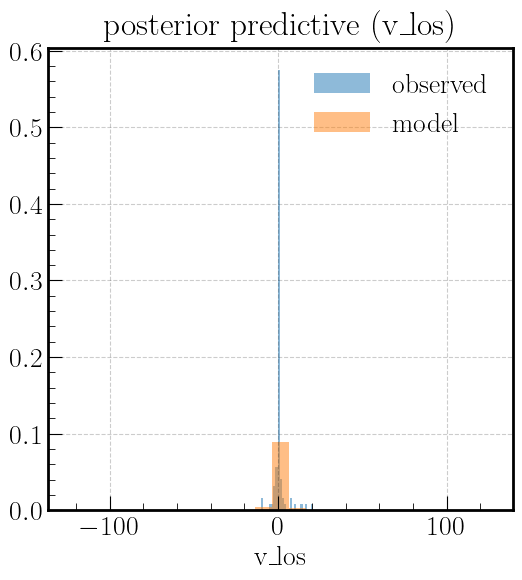

In [6]:
N = obs_pos.shape[0]
true_batch = StarBatch(
    pos=obs_pos, vel=obs_vel, vel_error=obs_err,
    theta=torch.tensor(theta_true).expand(N, -1),
    cond=cond_true.view(1, -1).expand(N, -1))
sampled = model.sample(true_batch, num_samples=20)   # (N, 20, [x, y, vlos])

plt.hist(obs_vel[:, 0].numpy(), bins=25, density=True, alpha=0.5, label='observed')
plt.hist(sampled[..., 2].flatten().numpy(), bins=25, density=True, alpha=0.5, label='model')
plt.xlabel('v_los'); plt.legend(); plt.title('posterior predictive (v_los)'); plt.show()

## MCMC on theta — physical-space prior

The model takes **physical** theta (it normalizes internally), so the prior is the physical simulation box (`simulate_8params_process.py` `PRIOR_MIN/MAX`, first 7 entries) — not derived from `norm_dict`, and no tilde/relative reparametrization (that only applies to sequential runs). `cond` is fixed to the measured value; stars are i.i.d. given theta so the galaxy log-like is the sum of per-star `model.log_prob`, done here outside the model.

In [7]:
# Physical prior box (simulate_8params_process.py PRIOR_MIN/MAX[:7]),
# order matches `labels`.
prior_min = np.array([0.5, 1.0, -1.0, -2.0,  3.0, -0.499, -1.0], dtype=np.float32)
prior_max = np.array([3.0, 10.0, 2.0,  2.0, 10.0,  1.0,    3.0], dtype=np.float32)
cond_fixed = cond_true.view(1, -1)   # measured half-light radius, held fixed


@torch.no_grad()
def galaxy_loglike(theta):
    """Sum of per-star log p(obs | theta, cond); theta in PHYSICAL units."""
    theta = torch.as_tensor(theta, dtype=torch.float32)
    W, N = theta.shape[0], obs_pos.shape[0]
    batch = StarBatch(
        pos=obs_pos.repeat(W, 1), vel=obs_vel.repeat(W, 1),
        vel_error=obs_err.repeat(W, 1),
        theta=theta.repeat_interleave(N, dim=0),
        cond=cond_fixed.expand(W * N, -1))
    return model.log_prob(batch).view(W, N).sum(dim=1)


def log_posterior(theta):
    theta = np.atleast_2d(theta)
    inside = np.all((theta >= prior_min) & (theta <= prior_max), axis=1)
    out = np.full(theta.shape[0], -np.inf)
    if inside.any():
        out[inside] = galaxy_loglike(theta[inside]).cpu().numpy()
    return out

In [8]:
ndim = len(labels)
nwalkers, nsteps, burnin = 40, 4000, 2000
rng = np.random.default_rng(0)
# init near truth (flow is lightly trained); clip to the prior box.
p0 = np.clip(
    theta_true + 0.05 * (prior_max - prior_min) * rng.standard_normal((nwalkers, ndim)),
    prior_min, prior_max)

# DE moves mix far better than the default stretch move on the correlated
# mass-anisotropy posterior (still a basic, gradient-free ensemble sampler).
moves = [(emcee.moves.DEMove(), 0.8), (emcee.moves.DESnookerMove(), 0.2)]
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior, vectorize=True, moves=moves)
sampler.run_mcmc(p0, nsteps, progress=True)
chain_phys = sampler.get_chain(discard=burnin, flat=True)
print('samples:', chain_phys.shape)


  0%|          | 0/4000 [00:00<?, ?it/s]


  0%|          | 6/4000 [00:00<01:12, 55.36it/s]


  0%|          | 13/4000 [00:00<01:05, 60.49it/s]


  0%|          | 20/4000 [00:00<01:03, 63.11it/s]


  1%|          | 28/4000 [00:00<00:57, 68.78it/s]


  1%|          | 37/4000 [00:00<00:53, 73.62it/s]

... (497 outputs left out)


100%|█████████▉| 3990/4000 [00:56<00:00, 70.54it/s]


100%|█████████▉| 3998/4000 [00:56<00:00, 72.28it/s]


100%|██████████| 4000/4000 [00:56<00:00, 71.13it/s]

samples: (80000, 7)


### MCMC diagnostics

Checks that the sampler mixed: acceptance fraction (~0.2-0.5 is healthy), integrated autocorrelation time vs chain length, and per-parameter split `r_hat` (→1) and effective sample size.

In [9]:
tau = sampler.get_autocorr_time(tol=0)
print(f'mean acceptance : {np.mean(sampler.acceptance_fraction):.3f}')
print(f'chain length    : {nsteps - burnin} steps x {nwalkers} walkers')
print(f'max autocorr tau : {np.max(tau):.1f} steps  '
      f'(want chain >> tau)')

post = sampler.get_chain(discard=burnin)   # (draw, walker, param)
print(f'\n{"param":>14} {"r_hat":>7} {"ess":>8}')
for i, lab in enumerate(labels):
    x = post[:, :, i]
    rhat = float(az.rhat(x, chain_axis=1, draw_axis=0))
    ess = float(az.ess(x, chain_axis=1, draw_axis=0))
    print(f'{lab:>14} {rhat:>7.3f} {ess:>8.0f}')

mean acceptance : 0.114
chain length    : 2000 steps x 40 walkers
max autocorr tau : 258.6 steps  (want chain >> tau)

         param   r_hat      ess
      dm_alpha   1.089      300
       dm_beta   1.360       91
      dm_gamma   1.369       90
    dm_log_rdm   1.090      319
   dm_log_rho0   1.072      418
      df_beta0   1.159      177


     df_log_ra   1.268      113


How to read this: `r_hat` near 1.0 with `ess` in the hundreds+ means the chains agree and are effectively independent. Large `r_hat`, or `ess` comparable to the autocorrelation time, means the chain is too short for the (broad, weakly informative) posterior of a lightly-trained flow -- train the flow longer, run more steps, or switch to a gradient-based sampler (HMC via the flow's autograd) for the sharper posterior of a well-trained flow.

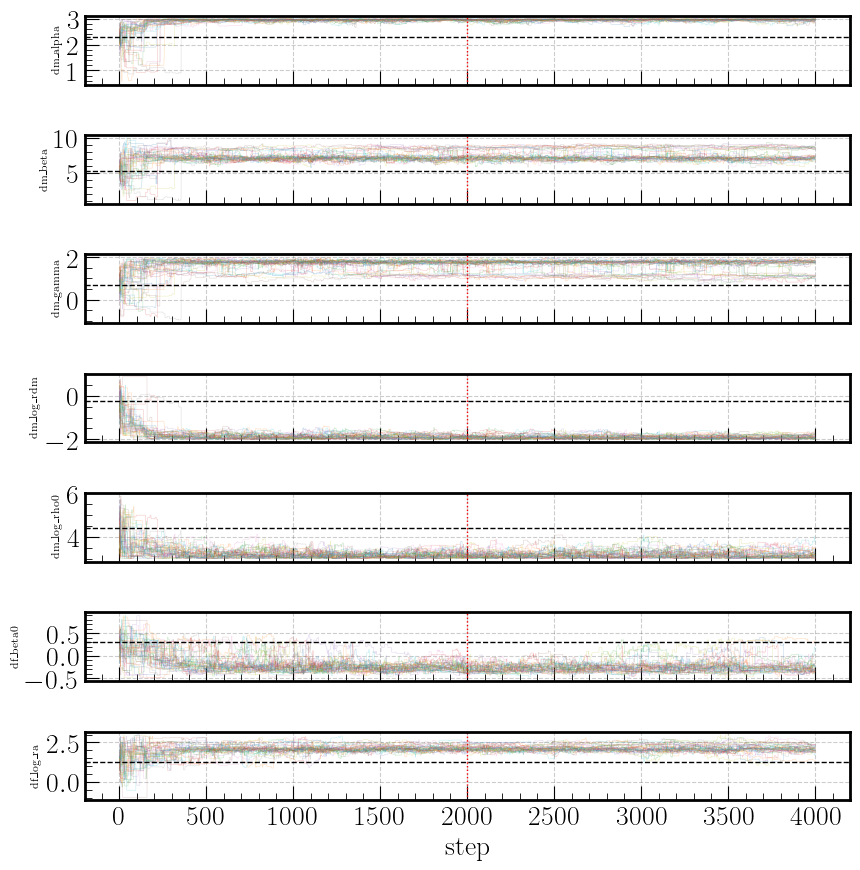

In [10]:
# trace plots: walkers over steps, truth (--) and burn-in (:) marked.
full = sampler.get_chain()   # (steps, walkers, param)
fig, axes = plt.subplots(ndim, 1, figsize=(9, 1.3 * ndim), sharex=True)
for i, (ax, lab) in enumerate(zip(axes, labels)):
    ax.plot(full[:, :, i], alpha=0.25, lw=0.4)
    ax.axhline(theta_true[i], color='k', ls='--', lw=1)
    ax.axvline(burnin, color='r', ls=':', lw=1)
    ax.set_ylabel(lab, fontsize=8)
axes[-1].set_xlabel('step')
plt.tight_layout(); plt.show()

## Corner plot

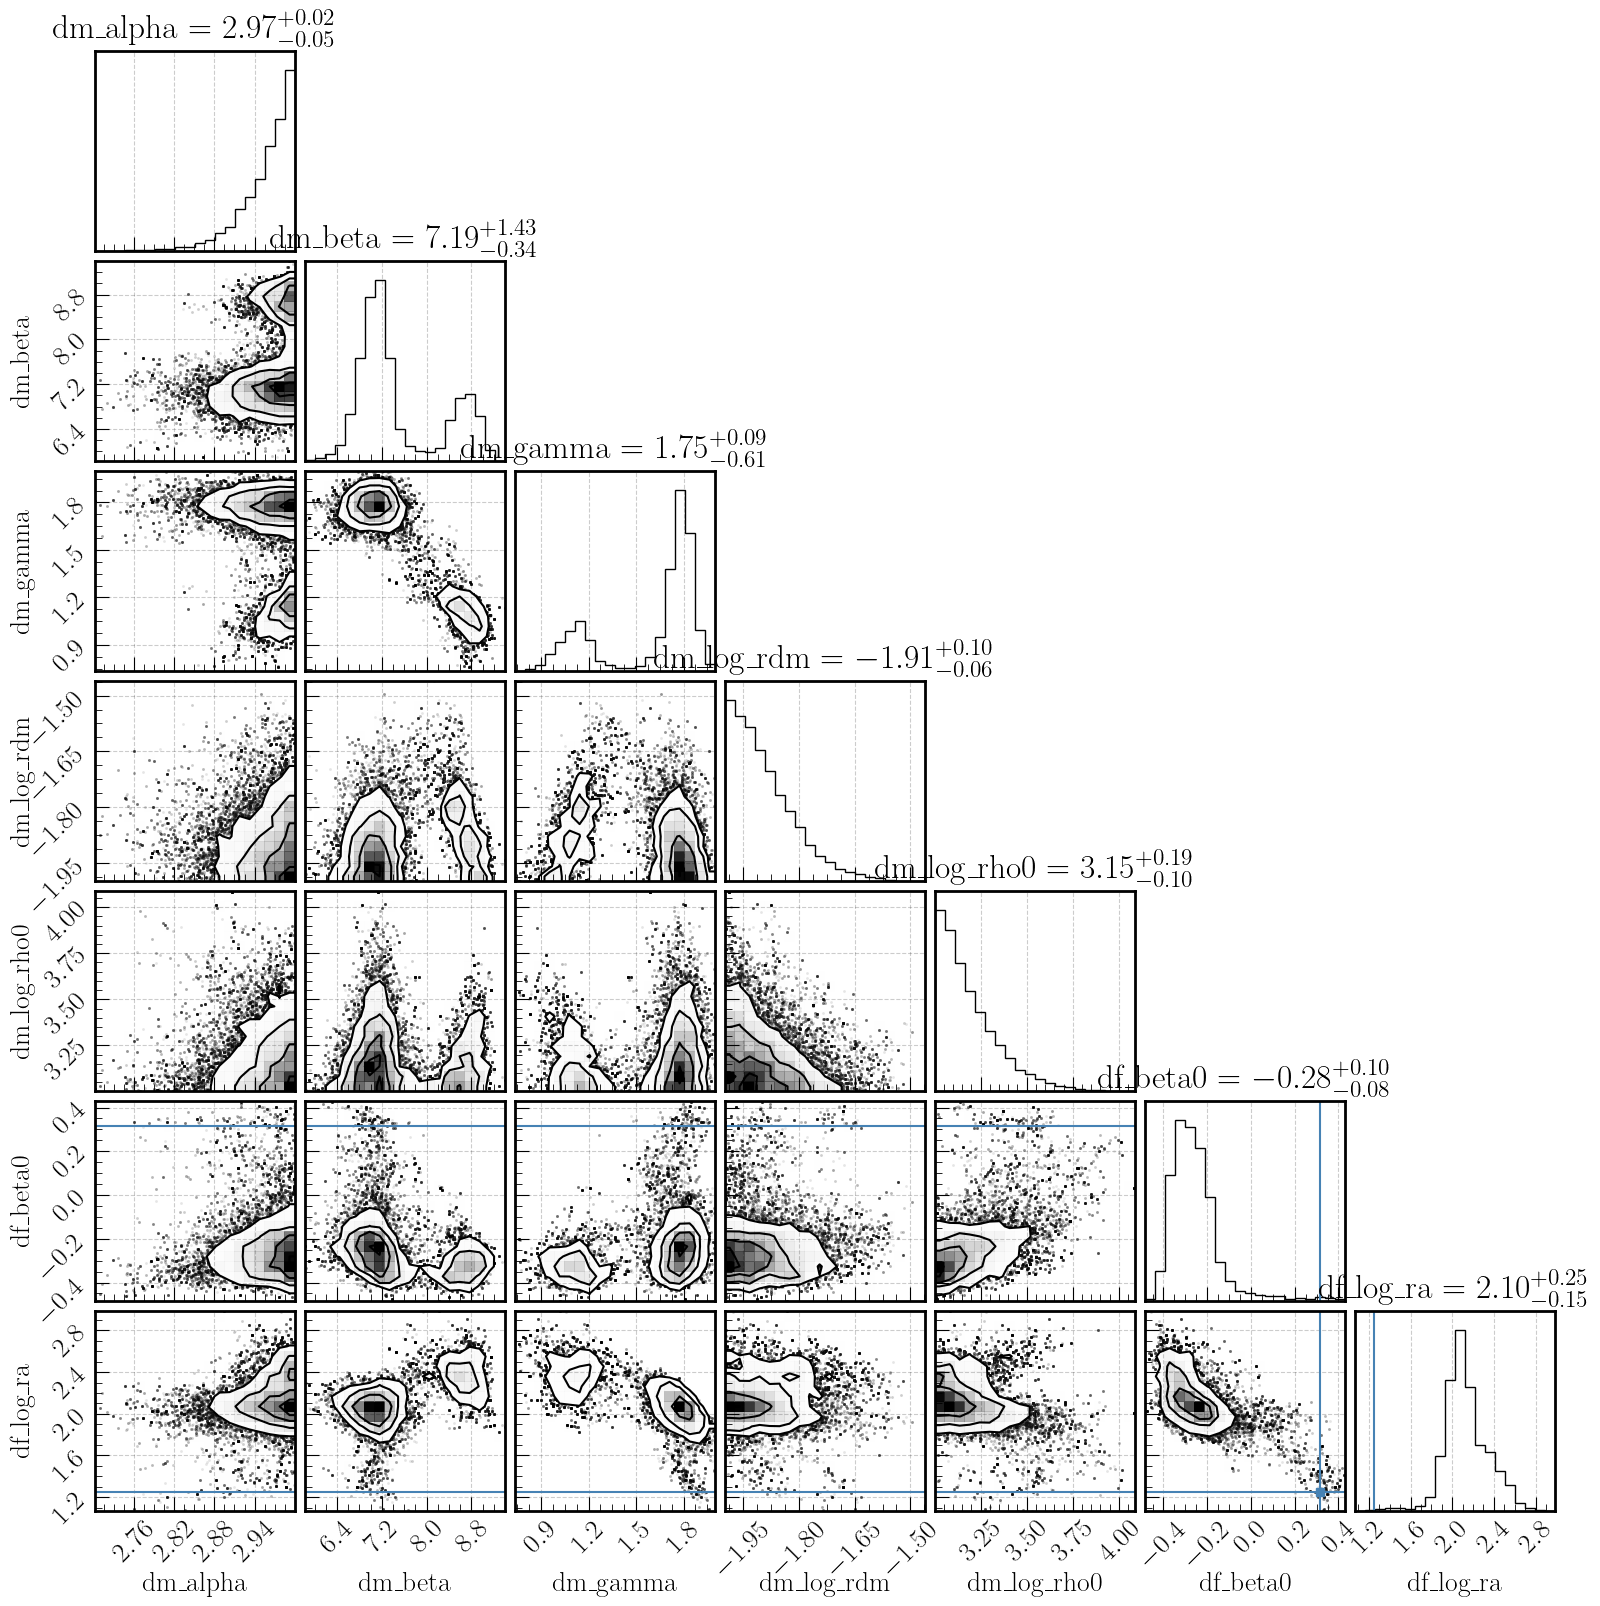

In [11]:
fig = corner.corner(chain_phys, labels=list(labels), truths=theta_true.tolist(),
                    show_titles=True, title_fmt='.2f')

## Density + anisotropy profiles

Analytic profiles (gNFW density, Osipkov-Merritt anisotropy) from `dsph_analysis/profiles.py`, evaluated over the posterior theta samples and compared to the truth. The anisotropy radius is placed in kpc via the fixed `cond` (`ra_kpc = 10**(df_log_ra + log_rstar_kpc)`); all parameters are log10.

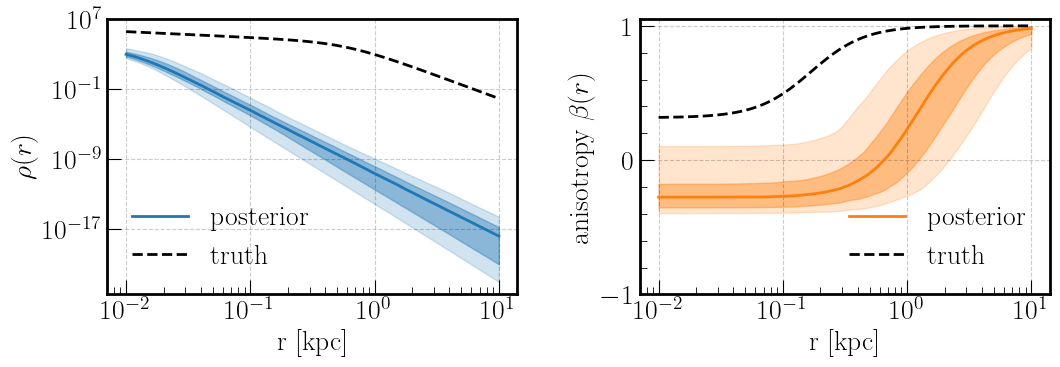

In [12]:
LN10 = np.log(10.0)


def ln_rho_gnfw(ln_r, ln_rho0, ln_rdm, gamma, alpha, beta):
    lnx = ln_r - ln_rdm
    return ln_rho0 - gamma * lnx - ((beta - gamma) / alpha) * np.log1p(np.exp(alpha * lnx))


def beta_osipkov_merritt(ln_r, beta_0, ln_ra):
    lnx2 = 2.0 * (ln_r - ln_ra)
    x2 = np.exp(np.clip(lnx2, -60, 60))
    return np.where(lnx2 > 10, 1.0, (beta_0 + x2) / (1.0 + x2))


def density_anisotropy(theta, log_rstar_kpc, r_kpc):
    """rho(r) and beta(r) for theta rows [a, b, g, log_rdm, log_rho0, beta0, log_ra]."""
    a, b, g, lrdm, lrho0, beta0, lra = np.asarray(theta, dtype=float).T
    ln_r = np.log(r_kpc)[None, :]
    rho = np.exp(ln_rho_gnfw(ln_r, (lrho0 * LN10)[:, None], (lrdm * LN10)[:, None],
                             g[:, None], a[:, None], b[:, None]))
    ln_ra = ((lra + log_rstar_kpc) * LN10)[:, None]   # anisotropy radius in kpc
    beta = beta_osipkov_merritt(ln_r, beta0[:, None], ln_ra)
    return rho, beta


def band(ax, x, samples, color, label):
    q = np.percentile(samples, [2.5, 16, 50, 84, 97.5], axis=0)
    ax.fill_between(x, q[0], q[4], alpha=0.2, color=color)
    ax.fill_between(x, q[1], q[3], alpha=0.4, color=color)
    ax.plot(x, q[2], color=color, lw=2, label=label)


r = np.logspace(-2, 1, 120)                       # 0.01 - 10 kpc
sub = chain_phys[rng.choice(len(chain_phys), size=500, replace=False)]
rho_post, beta_post = density_anisotropy(sub, float(cond_true), r)
rho_true, beta_true = density_anisotropy(theta_true[None, :], float(cond_true), r)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
band(ax1, r, rho_post, 'C0', 'posterior')
ax1.plot(r, rho_true[0], 'k--', lw=2, label='truth')
ax1.set_xscale('log'); ax1.set_yscale('log')
ax1.set_xlabel('r [kpc]'); ax1.set_ylabel(r'$\rho(r)$'); ax1.legend()
band(ax2, r, beta_post, 'C1', 'posterior')
ax2.plot(r, beta_true[0], 'k--', lw=2, label='truth')
ax2.set_xscale('log'); ax2.set_ylim(-1.0, 1.05)
ax2.set_xlabel('r [kpc]'); ax2.set_ylabel(r'anisotropy $\beta(r)$'); ax2.legend()
plt.tight_layout(); plt.show()